# 04 · From scores to decisions: tuning, calibration, costs and explanations

Notebooks 02–03 produced a good *ranking*. A fraud team needs more than that:

1. **A tuned model**, with hyperparameters chosen without peeking at the test period.
2. **Calibrated probabilities**, so a score of 0.3 means "30 % chance of fraud".
3. **A decision rule**: which transactions get blocked or reviewed. Choosing it is a
   business trade-off between fraud losses and review costs.
4. **An honest final number** on the untouched test period.
5. **Explanations**: why the model flagged a transaction.

This is also the first time we open the **test** period.

In [1]:
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix
from sklearn.model_selection import TimeSeriesSplit

from fraudkit.data import load_ulb, time_split
from fraudkit.metrics import bootstrap_ci, recall_at_alert_rate
from fraudkit.plotting import (
    CLASS_COLORS, INK, INK_2, MUTED, SEQUENTIAL, SERIES, SURFACE, finish, label_bars, set_style,
)

set_style()
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.float_format", "{:,.3f}".format)
SEED = 42

df = load_ulb()
FEATURES = [f"V{i}" for i in range(1, 29)] + ["LogAmount", "Hour"]
train, val, test = time_split(df)
X_tr, y_tr = train[FEATURES], train.Class.values
X_va, y_va = val[FEATURES], val.Class.values
X_te, y_te = test[FEATURES], test.Class.values

BASE_PARAMS = dict(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=40,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0)
FIXED = dict(random_state=SEED, verbose=-1, n_jobs=8)

/home/newf/projects/fraud-detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Hyperparameter tuning with Optuna, inside the training period only

**Optuna** searches the hyperparameter space with a *Tree-structured Parzen Estimator*.
It models which regions produced good scores so far and samples more trials there,
which is far more efficient than a grid.

The objective is the mean PR-AUC over a **3-fold rolling time split of the training
period**. Validation and test play no part in the search, so we can still use validation
to decide honestly whether tuning helped at all.

In [2]:
cv = TimeSeriesSplit(n_splits=3)


def cv_pr_auc(params):
    scores = []
    for i_tr, i_te in cv.split(X_tr):
        m = lgb.LGBMClassifier(**params, **FIXED).fit(X_tr.iloc[i_tr], y_tr[i_tr])
        scores.append(average_precision_score(y_tr[i_te], m.predict_proba(X_tr.iloc[i_te])[:, 1]))
    return float(np.mean(scores))


def objective(trial):
    return cv_pr_auc(dict(
        n_estimators=trial.suggest_int("n_estimators", 150, 800, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 64, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 300, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
    ))


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.enqueue_trial({k: v for k, v in BASE_PARAMS.items() if k != "subsample_freq"})  # trial 0 = notebook 02 settings
study.optimize(objective, n_trials=30)
print(f"default settings, CV PR-AUC: {study.trials[0].value:.3f}")
print(f"best trial #{study.best_trial.number}, CV PR-AUC: {study.best_value:.3f}")
study.best_params

default settings, CV PR-AUC: 0.791
best trial #29, CV PR-AUC: 0.804


{'n_estimators': 700,
 'learning_rate': 0.030012012974555635,
 'num_leaves': 5,
 'min_child_samples': 210,
 'subsample': 0.8344864174459148,
 'colsample_bytree': 0.5409279601616874,
 'reg_lambda': 0.360633870870589}

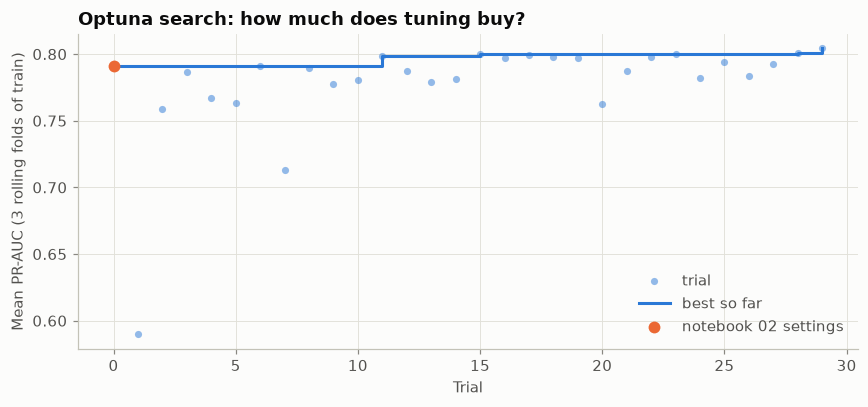

In [3]:
trials = study.trials_dataframe()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(trials.number, trials.value, s=22, color=SERIES[0], alpha=0.5, label="trial")
ax.plot(trials.number, trials.value.cummax(), color=SERIES[0], lw=2, drawstyle="steps-post",
        label="best so far")
ax.scatter([0], [trials.value[0]], s=60, color=SERIES[1], zorder=3, label="notebook 02 settings")
ax.set_xlabel("Trial"); ax.set_ylabel("Mean PR-AUC (3 rolling folds of train)")
ax.set_title("Optuna search: how much does tuning buy?")
ax.legend(loc="lower right")
finish(fig)

Now the honest check: fit both settings on the full training period and compare them on
the **validation** period, which the search never saw.

In [4]:
tuned_params = {**study.best_params, "subsample_freq": 1}
candidates = {"default (nb 02)": BASE_PARAMS, "Optuna-tuned": tuned_params}
fitted, val_rows = {}, {}
for name, params in candidates.items():
    fitted[name] = lgb.LGBMClassifier(**params, **FIXED).fit(X_tr, y_tr)
    s = fitted[name].predict_proba(X_va)[:, 1]
    pr, lo, hi = bootstrap_ci(average_precision_score, y_va, s, n_boot=500)
    val_rows[name] = {"val PR-AUC": pr, "lo": lo, "hi": hi}
val_cmp = pd.DataFrame(val_rows).T
chosen = val_cmp["val PR-AUC"].idxmax()
model = fitted[chosen]
print(f"carried forward: {chosen}")
val_cmp

carried forward: default (nb 02)


,val PR-AUC,lo,hi
default (nb 02),0.780,0.681,0.875
Optuna-tuned,0.756,0.653,0.860


**Reading it.** Optuna improved the cross-validated score (0.791 → 0.804), yet the tuned
model is *worse* on the validation period (0.756 vs 0.780). Both gaps are far inside the
bootstrap intervals. The search mostly fitted noise in three small training folds: a
textbook case of **overfitting the model-selection procedure**. We keep the notebook 02
defaults.

In fraud work, better *features* and better *decisions* usually matter more than better
hyperparameters, and the rest of this notebook is about decisions.

## 2. Calibration: making scores mean what they say

Notebook 02 showed that the fraud rate halved between the training and validation
periods. A model trained on the past therefore over-estimates risk on the future.

**Platt scaling** fits a one-feature logistic regression that maps the model's score to
a probability. We fit it on the **validation** period, the most recent data available
before test, which also re-centres the probabilities on the latest fraud rate.
`FrozenEstimator` keeps the already-trained LightGBM fixed; only the mapping is learned.

Platt is preferred over isotonic regression here: isotonic fits a free-form step
function, which over-fits with only ~60 frauds to learn from.

In [5]:
calibrated = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid").fit(X_va, y_va)
p_raw_te = model.predict_proba(X_te)[:, 1]
p_cal_te = calibrated.predict_proba(X_te)[:, 1]
p_cal_va = calibrated.predict_proba(X_va)[:, 1]

calib = pd.DataFrame({
    "expected frauds (sum of p)": [p_raw_te.sum(), p_cal_te.sum()],
    "actual frauds": [y_te.sum()] * 2,
    "Brier score": [brier_score_loss(y_te, p_raw_te), brier_score_loss(y_te, p_cal_te)],
    "PR-AUC": [average_precision_score(y_te, p_raw_te), average_precision_score(y_te, p_cal_te)],
}, index=["raw LightGBM", "Platt-calibrated"])
calib.style.format({"expected frauds (sum of p)": "{:.1f}", "Brier score": "{:.6f}", "PR-AUC": "{:.3f}"})

,expected frauds (sum of p),actual frauds,Brier score,PR-AUC
raw LightGBM,64.5,74,0.000337,0.812
Platt-calibrated,69.6,74,0.000341,0.812


**Reading it.** The raw model expects 64 frauds in the test period; 74 happened. After
Platt scaling on the more recent validation period, it expects 70. The *Brier score*
(mean squared error between probability and outcome, lower is better) improves slightly.
PR-AUC is identical before and after, because Platt scaling is monotonic and keeps the
ranking. Calibration changes what the numbers *mean*, not their
order, and the decision rules below rely on that meaning.

## 3. From probabilities to decisions: what does a mistake cost?

Every flagged transaction is reviewed by an analyst, and every missed fraud is lost money.
We use a simple, explicit cost model in euros:

| Outcome | Cost |
|---|---|
| Fraud **missed** (false negative) | the transaction's **amount** (the money is lost) |
| Transaction **flagged** (true or false positive) | **€5** of analyst time per review |
| Legit transaction not flagged | €0 |

Five decision policies compete. All of them use the same calibrated scores:

| Policy | Rule | Rationale |
|---|---|---|
| **No model** | flag nothing | the cost of doing nothing |
| **Fixed budget** | flag the riskiest 0.5 % | "our team can review this many" |
| **Flat-cost Bayes rule** | flag if *p* > 5 / 100 | flag when expected loss *p* × €100 exceeds review cost €5, assuming every fraud costs €100 |
| **Cost-tuned threshold** | flag if *p* > *t*, with *t* minimising € cost on validation | data-driven version of the above |
| **Amount-aware rule** | flag if *p* × amount > €5 | the Bayes rule with each transaction's own stake |

The amount-aware rule follows from decision theory. Flagging costs €5 for sure; not
flagging costs *amount* with probability *p*. Flag when the expected loss is larger. So a
€2,000 transaction is flagged at *p* > 0.25 %, while a €10 one needs *p* > 50 %.

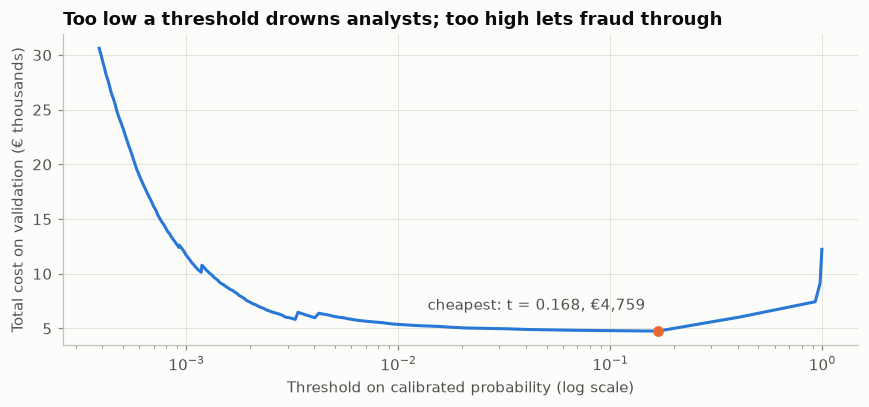

In [6]:
REVIEW_COST = 5.0


def euro_cost(flag, y, amount):
    missed = amount[(y == 1) & ~flag].sum()
    return {"alerts": int(flag.sum()), "frauds caught": int((flag & (y == 1)).sum()),
            "fraud € missed": missed, "review €": REVIEW_COST * flag.sum(),
            "total cost €": missed + REVIEW_COST * flag.sum()}


amt_va, amt_te = val.Amount.values, test.Amount.values

# Cost-tuned threshold: scan candidate thresholds on validation, keep the cheapest.
grid = np.unique(np.quantile(p_cal_va, np.linspace(0.9, 1, 400)))
val_costs = np.array([euro_cost(p_cal_va >= t, y_va, amt_va)["total cost €"] for t in grid])
t_star = grid[val_costs.argmin()]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(grid, val_costs / 1000, color=SERIES[0])
ax.scatter([t_star], [val_costs.min() / 1000], color=SERIES[1], s=50, zorder=3)
ax.annotate(f"cheapest: t = {t_star:.3f}, €{val_costs.min():,.0f}", (t_star, val_costs.min() / 1000),
            xytext=(-8, 14), textcoords="offset points", ha="right", color=INK_2)
ax.set_xscale("log")
ax.set_xlabel("Threshold on calibrated probability (log scale)")
ax.set_ylabel("Total cost on validation (€ thousands)")
ax.set_title("Too low a threshold drowns analysts; too high lets fraud through")
finish(fig)

The bottom of the curve is wide and flat: any threshold from about 1 % to 20 % costs
within a few hundred euros of the minimum. That is good news. The decision is robust, so
the exact optimum found on 57 validation frauds doesn't need to be trusted to three
decimals.

In [7]:
budget_t = np.quantile(p_cal_te, 1 - 0.005)
policies = {
    "No model": np.zeros_like(y_te, dtype=bool),
    "Fixed budget 0.5 %": p_cal_te >= budget_t,
    "Flat-cost Bayes (p > 5 %)": p_cal_te > REVIEW_COST / 100,
    "Cost-tuned threshold": p_cal_te >= t_star,
    "Amount-aware (p × amount > €5)": p_cal_te * amt_te > REVIEW_COST,
}
policy_tbl = pd.DataFrame({k: euro_cost(v, y_te, amt_te) for k, v in policies.items()}).T
policy_tbl["saving vs no model €"] = policy_tbl.loc["No model", "total cost €"] - policy_tbl["total cost €"]
policy_tbl.round(0).astype(int)

,alerts,frauds caught,fraud € missed,review €,total cost €,saving vs no model €
No model,0,0,7728,0,7728,0
Fixed budget 0.5 %,284,63,2367,1420,3787,3940
Flat-cost Bayes (p > 5 %),92,59,2398,460,2858,4870
Cost-tuned threshold,64,57,2637,320,2957,4770
Amount-aware (p × amount > €5),89,24,2442,445,2887,4841


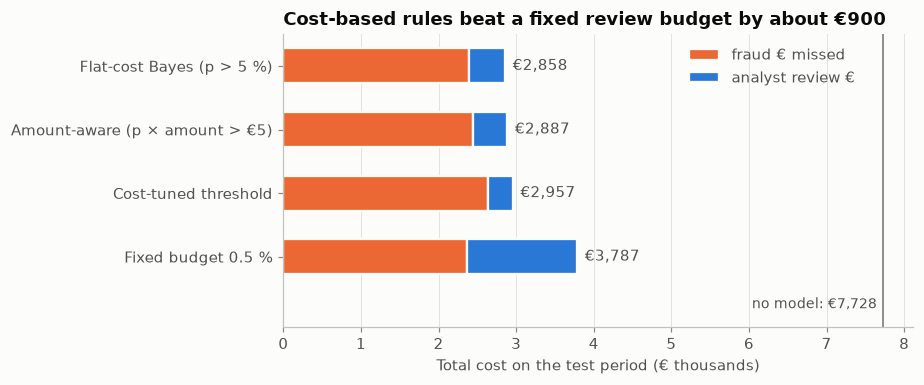

In [8]:
plot = policy_tbl.drop("No model")["total cost €"].sort_values(ascending=False)
no_model = policy_tbl.loc["No model", "total cost €"]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
missed = policy_tbl.loc[plot.index, "fraud € missed"]
review = policy_tbl.loc[plot.index, "review €"]
# Stacked segments separated by a thin surface-coloured edge rather than a border.
ax.barh(plot.index, missed / 1000, height=0.55, color=CLASS_COLORS[1], label="fraud € missed",
        edgecolor=SURFACE, linewidth=1.5)
ax.barh(plot.index, review / 1000, left=missed / 1000, height=0.55, color=SERIES[0],
        label="analyst review €", edgecolor=SURFACE, linewidth=1.5)
for i, v in enumerate(plot.values):
    ax.annotate(f"€{v:,.0f}", (v / 1000, i), xytext=(5, 0),
                textcoords="offset points", va="center", color=INK_2)
ax.axvline(no_model / 1000, color=MUTED, lw=1.2)
ax.annotate(f"no model: €{no_model:,.0f}", (no_model / 1000, -0.75), xytext=(-4, 0),
            textcoords="offset points", ha="right", va="center", color=INK_2, fontsize=9)
ax.set_ylim(-1.1, len(plot) - 0.5)
ax.set_xlabel("Total cost on the test period (€ thousands)")
ax.set_title("Cost-based rules beat a fixed review budget by about €900")
ax.legend(loc="upper right", bbox_to_anchor=(0.93, 1))
ax.grid(axis="y", visible=False)
finish(fig)

**Reading it.** The model is identical in every row; only the rule that turns scores into
actions changes.

* **Every policy cuts the €7.7k "no model" loss by half or more.** About €2.4k of fraud
  is lost under *every* rule. Those are the frauds the model ranks as legit (section 5
  shows one), and no threshold reaches them.
* **The fixed 0.5 % budget is the most expensive rule.** It raises 284 alerts to catch 63
  frauds. The cost-based rules raise 64–92 alerts and catch almost as many, saving about
  €900 (24 %) on this period. Deriving the threshold from costs is free once the
  probabilities are calibrated.
* **The three cost-based rules are tied.** Differences of ~€100 are noise with 74
  frauds. The simple flat-cost Bayes rule (*p* > 5 %) needed no tuning at all, which is
  the practical benefit of calibration.
* **The amount-aware rule reaches the same cost by catching 24 frauds instead of 59.**
  It deliberately ignores small frauds, because a €1 loss doesn't pay for a €5 review.
  On paper that is optimal. In practice the ignored frauds are mostly **card tests**
  (notebook 01), which announce that a card is compromised and larger fraud will follow.
  A real cost model would value the *future* loss a card test predicts. The lesson: an
  "optimal" rule is only as good as its cost model.

## 4. Final evaluation on the untouched test period

In [9]:
pr, pr_lo, pr_hi = bootstrap_ci(average_precision_score, y_te, p_cal_te)
rec, rec_lo, rec_hi = bootstrap_ci(lambda y, s: recall_at_alert_rate(y, s, 0.005), y_te, p_cal_te)
va_pr = average_precision_score(y_va, p_cal_va)
final = pd.DataFrame({
    "validation": [va_pr, recall_at_alert_rate(y_va, p_cal_va, 0.005)],
    "test": [pr, rec],
    "test 95 % CI": [f"{pr_lo:.3f}–{pr_hi:.3f}", f"{rec_lo:.3f}–{rec_hi:.3f}"],
}, index=["PR-AUC", "recall @ 0.5 % budget"])
final

,validation,test,test 95 % CI
PR-AUC,0.780,0.812,0.726–0.891
recall @ 0.5 % budget,0.807,0.851,0.771–0.924


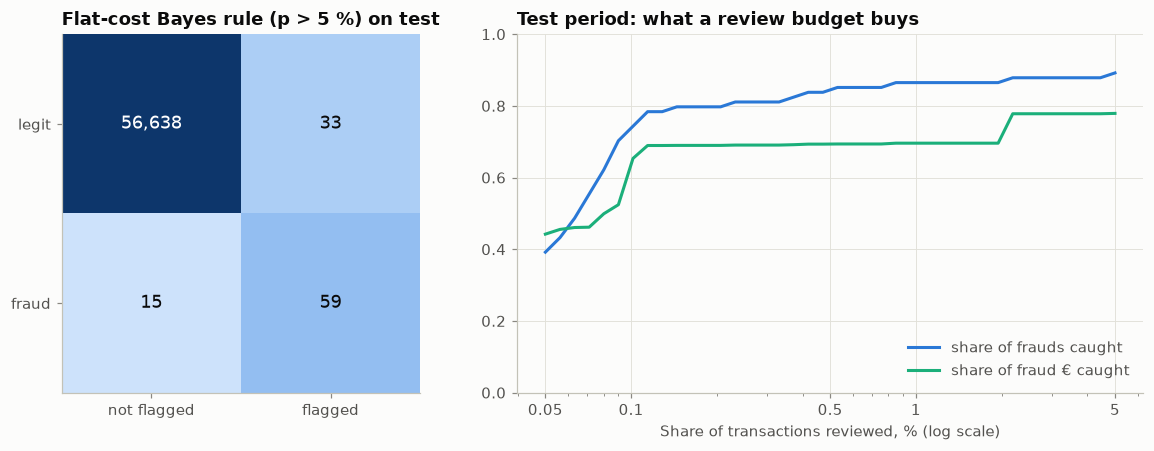

In [10]:
flag = policies["Flat-cost Bayes (p > 5 %)"]
cm = confusion_matrix(y_te, flag)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.imshow(np.log10(cm + 1), cmap=SEQUENTIAL)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=12,
            color="white" if np.log10(v + 1) > np.log10(cm.max() + 1) / 2 else INK)
ax.set_xticks([0, 1], ["not flagged", "flagged"]); ax.set_yticks([0, 1], ["legit", "fraud"])
ax.set_title("Flat-cost Bayes rule (p > 5 %) on test"); ax.grid(False)

ax = axes[1]
rates = np.geomspace(0.0005, 0.05, 40)
ax.plot(rates * 100, [recall_at_alert_rate(y_te, p_cal_te, a) for a in rates], color=SERIES[0],
        label="share of frauds caught")
order = np.argsort(-p_cal_te)
caught_amt = [amt_te[order[:int(np.ceil(a * len(order)))]][y_te[order[:int(np.ceil(a * len(order)))]] == 1].sum()
              / amt_te[y_te == 1].sum() for a in rates]
ax.plot(rates * 100, caught_amt, color=SERIES[2], label="share of fraud € caught")
ax.set_xscale("log")
ax.set_xticks([0.05, 0.1, 0.5, 1, 5], ["0.05", "0.1", "0.5", "1", "5"])
ax.set_ylim(0, 1)
ax.set_xlabel("Share of transactions reviewed, % (log scale)")
ax.set_title("Test period: what a review budget buys")
ax.legend(loc="lower right")
finish(fig)

**Reading it.** The confusion matrix uses a log colour scale, because the legit/legit cell
is three orders of magnitude larger than the rest. The budget curve compares the *share
of frauds* with the *share of fraud euros* caught. The gap between the two lines shows
whether the model is better at catching small frauds or big ones. Here the euro curve
lies below the count curve: the model catches 85 % of frauds but only ~70 % of fraud
euros at a 0.5 % budget. The frauds it misses tend to be the larger ones, which is worth
flagging to the business.

The test-period scores (PR-AUC 0.81, recall 0.85) are slightly *higher* than validation.
That is no reason to celebrate: the confidence intervals overlap almost completely, and
with 74 frauds a few easy or hard cases move the number by several points.

## 5. Explainability with SHAP

**SHAP** (SHapley Additive exPlanations) splits each prediction into contributions from
each feature, using Shapley values from game theory. Each feature's contribution is its
average marginal effect over all orders in which features could be added. For tree
models, `TreeExplainer` computes them exactly and fast.

Contributions are in **log-odds** (the raw score before the sigmoid) and add up exactly:
`base value + Σ SHAP values = model output`. We explain the uncalibrated LightGBM; Platt
scaling is a monotonic transform on top and doesn't change which features drive a
decision.

*Caveat for this dataset:* V1–V28 are anonymised, so we can say *which component*
drives a decision but not what it means in business terms. With real features (see
project 2), the same plots become an analyst's investigation tool.

In [11]:
explainer = shap.TreeExplainer(model)
sample_idx = np.r_[np.where(y_te == 1)[0],
                   np.random.default_rng(SEED).choice(np.where(y_te == 0)[0], 3000, replace=False)]
sv = explainer(X_te.iloc[sample_idx])

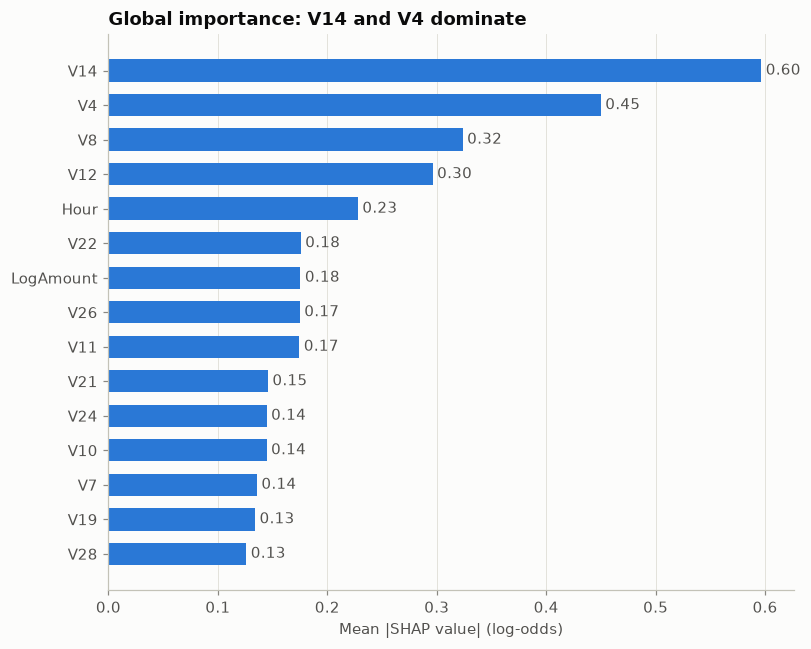

In [12]:
mean_abs = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 6))
top = mean_abs.tail(15)
bars = ax.barh(top.index, top.values, color=SERIES[0], height=0.65)
label_bars(ax, bars, fmt="{:.2f}", horizontal=True)
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("Global importance: V14 and V4 dominate")
ax.grid(axis="y", visible=False)
finish(fig)

Compare this ranking with notebook 01's KS screen. V14, V4 and V12 lead again, as the
univariate analysis suggested. Two differences are instructive:
* **V10 and V17 rank much lower here** despite high KS scores. Notebook 01 showed they
  are strongly correlated with V14 *within fraud*, so once the trees split on V14 they
  add little new information. SHAP shares the credit among correlated features rather
  than repeating it.
* **V8 and `Hour` rank higher** than their KS scores suggest. They matter in combination
  with other features, the kind of interaction a univariate screen can't see.

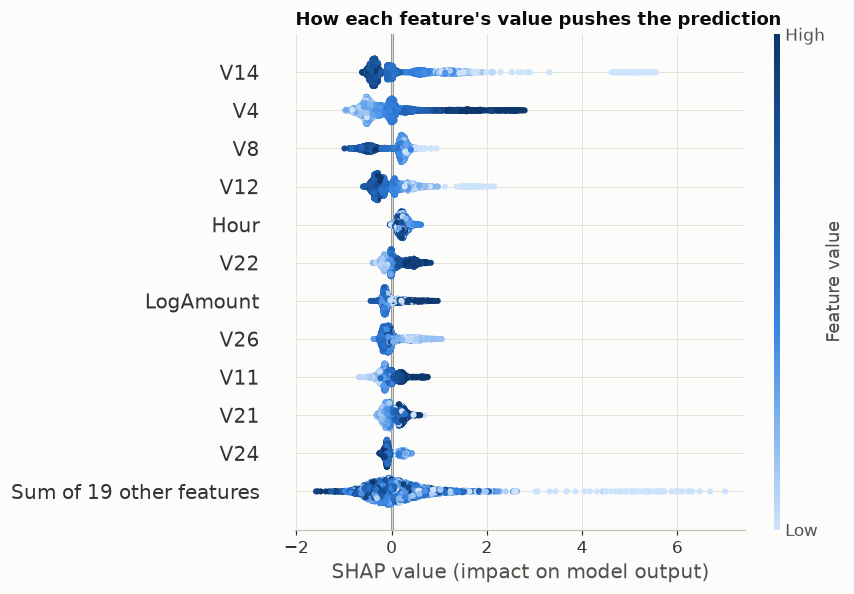

In [13]:
plt.figure()
shap.plots.beeswarm(sv, max_display=12, show=False, color=SEQUENTIAL)
ax = plt.gca()
ax.set_title("How each feature's value pushes the prediction", loc="left", fontweight="bold")
plt.gcf().set_size_inches(8, 5.5)
finish()

**How to read a beeswarm.** Each dot is one transaction; horizontal position is that
feature's SHAP value (right = towards fraud). Colour is the feature's own value (dark =
high). For V14, the low (light) values sit on the right, so **very negative V14 pushes
towards fraud**, exactly the shift seen in notebook 01's histograms.

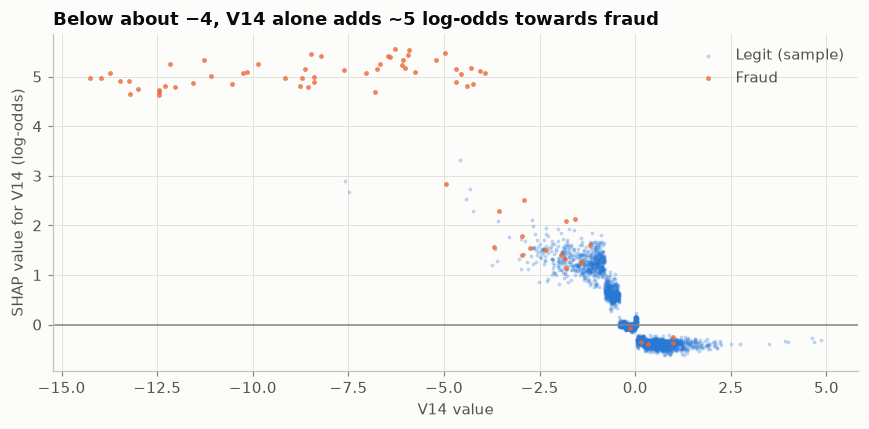

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
j = FEATURES.index("V14")
is_fraud = y_te[sample_idx] == 1
for c, m in [(0, ~is_fraud), (1, is_fraud)]:
    ax.scatter(sv.data[m, j], sv.values[m, j], s=10 if c else 6, alpha=0.8 if c else 0.3,
               color=CLASS_COLORS[c], label="Fraud" if c else "Legit (sample)")
ax.axhline(0, color=MUTED, lw=1)
ax.set_xlabel("V14 value"); ax.set_ylabel("SHAP value for V14 (log-odds)")
ax.set_title("Below about −4, V14 alone adds ~5 log-odds towards fraud")
ax.legend(loc="upper right")
finish(fig)

### Local explanations: one caught fraud, one missed fraud

A **waterfall** starts at the base value (the average log-odds) and adds one feature's
contribution at a time until it reaches this transaction's score. This is what an analyst
would see next to an alert.

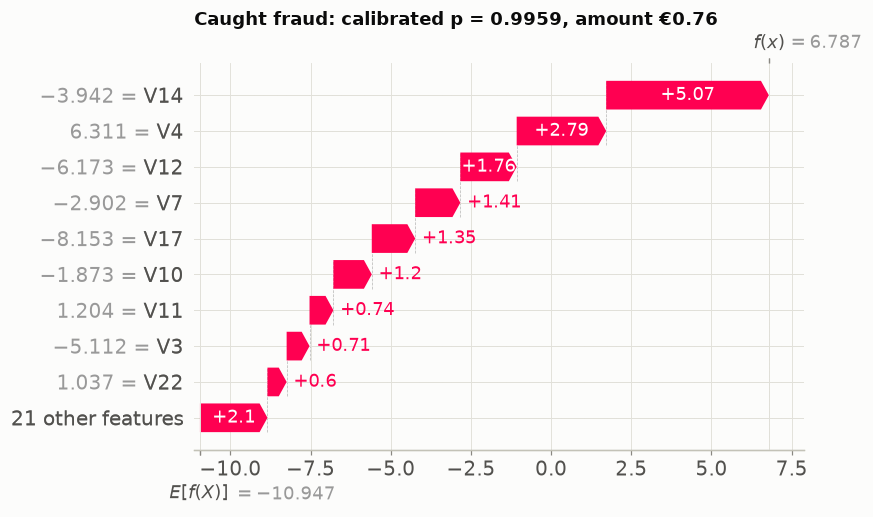

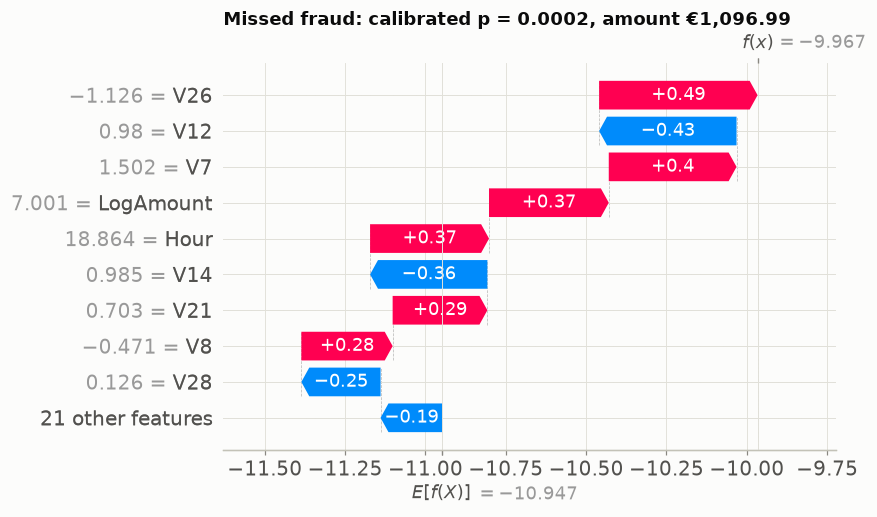

In [15]:
p_sample = p_cal_te[sample_idx]
fraud_pos = np.where(is_fraud)[0]
caught = fraud_pos[np.argmax(p_sample[fraud_pos])]
missed = fraud_pos[np.argmin(p_sample[fraud_pos])]

for label, i in [("Caught fraud", caught), ("Missed fraud", missed)]:
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.gcf().set_size_inches(8, 4.8)
    plt.title(f"{label}: calibrated p = {p_sample[i]:.4f}, amount €{test.Amount.values[sample_idx[i]]:,.2f}",
              loc="left", fontweight="bold")
    finish()

**Reading it.** Both waterfalls start at the same base value, about −11 log-odds. That
is simply how rare fraud is.

* **The caught fraud** is pushed up by nine components at once (V14 +5, V4 +2.8, V12,
  V7, V17, V10…), which is the multi-component "fraud signature" from notebook 01's
  correlation heatmap. Note its amount: **€0.76**, a typical card test. The model is
  99.6 % sure, yet the amount-aware rule from section 3 would *not* flag it.
* **The missed fraud** (€1,097) has contributions in both directions, none larger than
  ±0.5. V14 even pushes towards legit. It ends up 1 log-odd above the base, which is
  still a probability of 0.02 %. Nothing in these 30 features distinguishes it. Catching
  such cases needs new information, such as cardholder history, device or merchant data,
  rather than a better model.

## 6. Project summary

| Question | Answer from this project |
|---|---|
| How to evaluate? | PR-AUC and recall at a review budget, with bootstrap intervals; never accuracy. Split by time. |
| How to handle imbalance? | It depends on the model: class weights help logistic regression; LightGBM is best unweighted. Undersampling and SMOTE didn't pay off. |
| Do we need labels? | LOF on legit history catches most fraud without labels, but just 5 labelled frauds beat it. |
| Does tuning help? | Not here: Optuna won in cross-validation and lost on validation, all within noise. |
| How to decide? | Calibrate, then derive the threshold from costs. That saved ~24 % against a fixed review budget. An "optimal" rule is only as good as its cost model (card tests). |
| How good is it? | Test PR-AUC 0.81 (95 % CI 0.73–0.89); 85 % of frauds caught when 0.5 % of transactions are reviewed. |
| Why did the model flag it? | SHAP: a consistent multi-component fraud signature. Misses are frauds that look legit in every feature. |

**Limitations**
* Two days of data: the validation and test periods hold only 57 and 74 frauds, hence the
  wide intervals. Seasonality and long-term drift can't be studied.
* Anonymised features prevent business interpretation and feature engineering. Project 2
  (IEEE-CIS) addresses exactly that.
* The validation period is used three times (model choice, calibration, threshold). With
  more data, each would get its own window, and the final model would be retrained on all
  data up to deployment.
* The cost model is simplified: no chargeback fees, no customer-friction cost for false
  alarms, no value placed on catching card tests.